In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
stores = pd.read_csv('/content/dim_stores.csv')
skus = pd.read_csv('/content/dim_skus.csv')
suppliers = pd.read_csv('/content/dim_suppliers.csv')
events = pd.read_csv('/content/dim_events.csv')
inventory = pd.read_csv('/content/fact_inventory_daily.csv')

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [3]:
print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Inventory:", inventory.shape)

Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Inventory: (21600, 16)


In [4]:
# Display column names of all datasets

print("STORE COLUMNS:")
print(stores.columns.tolist())

print("\nSKU COLUMNS:")
print(skus.columns.tolist())

print("\nSUPPLIER COLUMNS:")
print(suppliers.columns.tolist())

print("\nEVENT COLUMNS:")
print(events.columns.tolist())

print("\nINVENTORY COLUMNS:")
print(inventory.columns.tolist())

STORE COLUMNS:
['store_id', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders']

SKU COLUMNS:
['sku_id', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id']

SUPPLIER COLUMNS:
['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']

EVENT COLUMNS:
['date', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

INVENTORY COLUMNS:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [5]:
# Check information about datasets

print("STORES DATASET")
stores.info()

print("\nSKUS DATASET")
skus.info()

print("\nSUPPLIERS DATASET")
suppliers.info()

print("\nEVENTS DATASET")
events.info()

print("\nINVENTORY DATASET")
inventory.info()

STORES DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   store_id               12 non-null     object
 1   city                   12 non-null     object
 2   city_display           12 non-null     object
 3   city_tier              12 non-null     object
 4   store_size             12 non-null     object
 5   sqft                   12 non-null     int64 
 6   opened_year            12 non-null     int64 
 7   baseline_daily_orders  12 non-null     int64 
dtypes: int64(3), object(5)
memory usage: 900.0+ bytes

SKUS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sku_id            60 non-null     object 
 1   sku_name          60 non-null     object 
 2   category 

In [6]:
# Check missing values in all datasets

datasets = {
    'Stores': stores,
    'SKUs': skus,
    'Suppliers': suppliers,
    'Events': events,
    'Inventory': inventory
}

for name, df in datasets.items():
    print("\n", name)
    print(df.isnull().sum())


 Stores
store_id                 0
city                     0
city_display             0
city_tier                0
store_size               0
sqft                     0
opened_year              0
baseline_daily_orders    0
dtype: int64

 SKUs
sku_id              0
sku_name            0
category            0
unit_price_inr      0
shelf_life_days     0
is_perishable       0
festive_relevant    0
popularity_tier     0
supplier_id         0
dtype: int64

 Suppliers
supplier_id                0
supplier_name              0
categories_supplied        0
reliability_score          3
base_lead_time_days        0
lead_time_variance_days    0
dtype: int64

 Events
date                         0
event_name                   0
event_type                   0
demand_multiplier_festive    0
demand_multiplier_other      0
dtype: int64

 Inventory
date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock           

In [7]:
# Check duplicate records

for name, df in datasets.items():
    print(name, "Duplicates:", df.duplicated().sum())

Stores Duplicates: 0
SKUs Duplicates: 0
Suppliers Duplicates: 0
Events Duplicates: 0
Inventory Duplicates: 0


In [8]:
# Count each target class

print(inventory['stockout_risk'].value_counts())

# Calculate percentage distribution

print(inventory['stockout_risk'].value_counts(normalize=True) * 100)

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64
stockout_risk
Safe        65.421296
At-Risk     24.009259
Imminent    10.569444
Name: proportion, dtype: float64


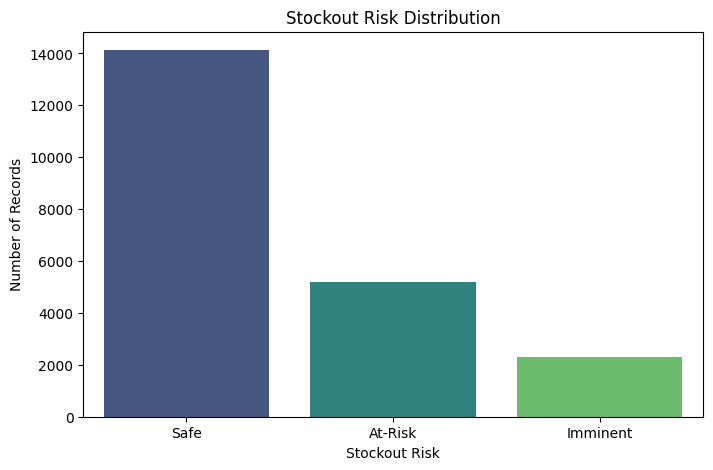

In [9]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=inventory,
    x='stockout_risk',
    hue='stockout_risk',
    palette='viridis',
    legend=False
)

plt.title('Stockout Risk Distribution')
plt.xlabel('Stockout Risk')
plt.ylabel('Number of Records')
plt.show()

In [10]:
# Check city names before cleaning

print("Before Cleaning:")
print(stores[['city', 'city_display']])

Before Cleaning:
         city city_display
0      Mumbai       Mumbai
1      Mumbai       Mumbai
2   Bengaluru    BENGALURU
3   Bengaluru    Bengaluru
4       Delhi        Delhi
5       Delhi        Delhi
6        Pune         Pune
7        Pune         Pune
8   Hyderabad    hyderabad
9   Hyderabad    Hyderabad
10    Chennai      Chennai
11    Chennai      Chennai


In [11]:
# Standardize city names

stores['city_display'] = stores['city_display'].str.strip().str.title()

print("After Cleaning:")
print(stores[['city', 'city_display']])

After Cleaning:
         city city_display
0      Mumbai       Mumbai
1      Mumbai       Mumbai
2   Bengaluru    Bengaluru
3   Bengaluru    Bengaluru
4       Delhi        Delhi
5       Delhi        Delhi
6        Pune         Pune
7        Pune         Pune
8   Hyderabad    Hyderabad
9   Hyderabad    Hyderabad
10    Chennai      Chennai
11    Chennai      Chennai


In [12]:
# Check missing reliability scores

print(suppliers['reliability_score'].isnull().sum())

3


In [13]:
# Convert reliability score into numeric values

suppliers['reliability_score'] = pd.to_numeric(
    suppliers['reliability_score'],
    errors='coerce'
)

print(suppliers[['supplier_name', 'reliability_score']])

                supplier_name  reliability_score
0              Fresh Farms Co               0.92
1   Green Valley Distributors               0.93
2        Metro Dairy Supplies               0.90
3        Sunrise Agro Traders               0.70
4         National Snacks Ltd               0.66
5       QuickBev Distributors                NaN
6          CarePlus Wholesale               0.67
7          HomeShine Supplies               0.73
8        Golden Grain Traders               0.72
9          Daily Bakes Supply               0.66
10      Coastal Foods Pvt Ltd               0.83
11          Bharat Staples Co               0.63
12    Urban FMCG Distributors               0.91
13        Prime Personal Care                NaN
14       Regional Produce Hub                NaN


In [14]:
# Calculate median reliability score

median_reliability = suppliers['reliability_score'].median()

# Fill missing values

suppliers['reliability_score'] = suppliers['reliability_score'].fillna(
    median_reliability
)

print("Missing values after cleaning:",
      suppliers['reliability_score'].isnull().sum())

Missing values after cleaning: 0


In [15]:
# Check missing lead time values

print(inventory['lead_time_days_actual'].isnull().sum())

19899


In [16]:
# Check duplicate records

for name, df in datasets.items():
    print(name, ":", df.duplicated().sum())

Stores : 0
SKUs : 0
Suppliers : 0
Events : 0
Inventory : 0


In [17]:
# Convert date columns

inventory['date'] = pd.to_datetime(inventory['date'])
events['date'] = pd.to_datetime(events['date'])

print("Date columns converted successfully!")

Date columns converted successfully!


In [18]:
print("STORES MISSING VALUES:")
print(stores.isnull().sum())

print("\nSUPPLIERS MISSING VALUES:")
print(suppliers.isnull().sum())

print("\nSUPPLIER RELIABILITY DATA TYPE:")
print(suppliers['reliability_score'].dtype)

print("\nDATE DATA TYPE:")
print(inventory['date'].dtype)

print("\nFINAL DATASET SHAPES:")
print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Inventory:", inventory.shape)

STORES MISSING VALUES:
store_id                 0
city                     0
city_display             0
city_tier                0
store_size               0
sqft                     0
opened_year              0
baseline_daily_orders    0
dtype: int64

SUPPLIERS MISSING VALUES:
supplier_id                0
supplier_name              0
categories_supplied        0
reliability_score          0
base_lead_time_days        0
lead_time_variance_days    0
dtype: int64

SUPPLIER RELIABILITY DATA TYPE:
float64

DATE DATA TYPE:
datetime64[ns]

FINAL DATASET SHAPES:
Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Inventory: (21600, 16)


In [19]:
# Merge inventory with stores

master = inventory.merge(
    stores,
    on='store_id',
    how='left',
    validate='many_to_one'
)

print("Stores merged successfully!")
print(master.shape)

Stores merged successfully!
(21600, 23)


In [20]:
# Rename supplier_id in SKU table to avoid duplicate column names

skus_merged = skus.rename(
    columns={'supplier_id': 'sku_supplier_id'}
)

# Merge SKU information

master = master.merge(
    skus_merged,
    on='sku_id',
    how='left',
    validate='many_to_one'
)

print("SKU data merged successfully!")
print(master.shape)

SKU data merged successfully!
(21600, 31)


In [21]:
# Merge supplier information

master = master.merge(
    suppliers,
    on='supplier_id',
    how='left',
    validate='many_to_one'
)

print("Supplier data merged successfully!")
print(master.shape)

Supplier data merged successfully!
(21600, 36)


In [22]:
# Merge event information using date

master = master.merge(
    events,
    on='date',
    how='left',
    validate='many_to_one'
)

print("Event data merged successfully!")
print(master.shape)

Event data merged successfully!
(21600, 40)


In [23]:
# Check final master dataset

print("Final Master Dataset Shape:", master.shape)

print("\nFirst 5 Rows:")
display(master.head())

print("\nTotal Missing Values:")
print(master.isnull().sum().sum())

print("\nTotal Duplicate Rows:")
print(master.duplicated().sum())

Final Master Dataset Shape: (21600, 40)

First 5 Rows:


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,sku_supplier_id,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0



Total Missing Values:
19899

Total Duplicate Rows:
0


In [24]:
# Check whether SKU and inventory supplier IDs match

mismatch = master['supplier_id'] != master['sku_supplier_id']

print("Supplier ID mismatches:", mismatch.sum())

Supplier ID mismatches: 0


In [25]:
# Stockout risk distribution

risk_counts = master['stockout_risk'].value_counts()

print(risk_counts)

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64


In [26]:
risk_percentage = master['stockout_risk'].value_counts(
    normalize=True
) * 100

print(risk_percentage.round(2))

stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64


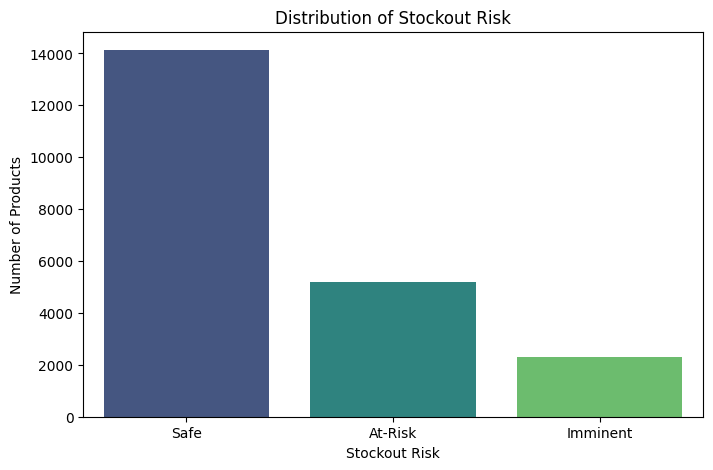

In [27]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=master,
    x='stockout_risk',
    hue='stockout_risk',
    palette='viridis',
    legend=False
)

plt.title('Distribution of Stockout Risk')
plt.xlabel('Stockout Risk')
plt.ylabel('Number of Products')
plt.show()

In [28]:
# Calculate stockout risk during festival and non-festival days

festival_analysis = master.groupby(
    'is_festival_week'
)['stockout_risk'].apply(
    lambda x: (x == 'Imminent').mean() * 100
)

print(festival_analysis)

is_festival_week
N     9.511633
Y    23.309179
Name: stockout_risk, dtype: float64


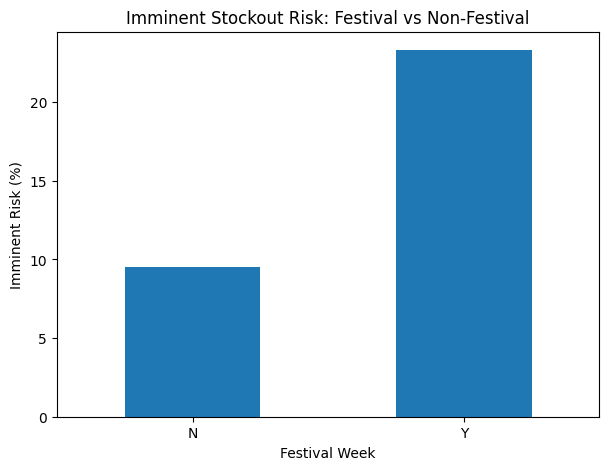

In [29]:
plt.figure(figsize=(7,5))

festival_analysis.plot(kind='bar')

plt.title('Imminent Stockout Risk: Festival vs Non-Festival')
plt.xlabel('Festival Week')
plt.ylabel('Imminent Risk (%)')
plt.xticks(rotation=0)
plt.show()

In [30]:
# Categorize supplier reliability

master['reliability_category'] = pd.cut(
    master['reliability_score'],
    bins=[0, 0.75, 0.85, 1.0],
    labels=['Low', 'Mid', 'High'],
    include_lowest=True
)

print(master['reliability_category'].value_counts())

reliability_category
Low     15840
High     4320
Mid      1440
Name: count, dtype: int64


In [31]:
supplier_analysis = master.groupby(
    'reliability_category',
    observed=False
)['stockout_risk'].apply(
    lambda x: (x == 'Imminent').mean() * 100
)

print(supplier_analysis)

reliability_category
Low     13.074495
Mid      3.263889
High     3.819444
Name: stockout_risk, dtype: float64


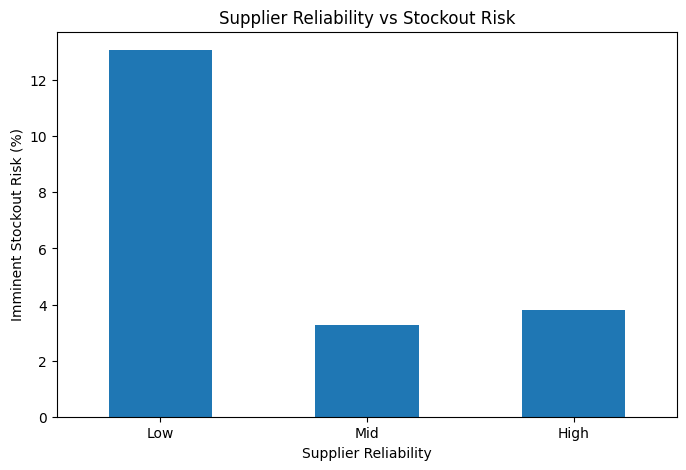

In [32]:
plt.figure(figsize=(8,5))

supplier_analysis.plot(kind='bar')

plt.title('Supplier Reliability vs Stockout Risk')
plt.xlabel('Supplier Reliability')
plt.ylabel('Imminent Stockout Risk (%)')
plt.xticks(rotation=0)
plt.show()

In [33]:
# Calculate risk for perishable and non-perishable products

perishable_analysis = master.groupby(
    'is_perishable'
)['stockout_risk'].apply(
    lambda x: (x == 'Imminent').mean() * 100
)

print(perishable_analysis)

is_perishable
N     9.298246
Y    12.765152
Name: stockout_risk, dtype: float64


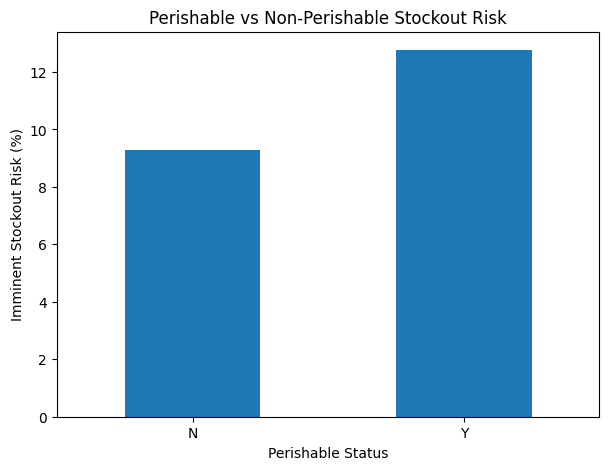

In [34]:
plt.figure(figsize=(7,5))

perishable_analysis.plot(kind='bar')

plt.title('Perishable vs Non-Perishable Stockout Risk')
plt.xlabel('Perishable Status')
plt.ylabel('Imminent Stockout Risk (%)')
plt.xticks(rotation=0)
plt.show()

In [35]:
category_analysis = master.groupby(
    'category'
)['stockout_risk'].apply(
    lambda x: (x == 'Imminent').mean() * 100
).sort_values(ascending=False)

print(category_analysis)

category
Bakery                 26.111111
Beverages              14.548611
Snacks                 10.185185
Home Care               8.518519
Fruits & Vegetables     7.932099
Dairy                   7.539683
Personal Care           6.785714
Staples                 5.833333
Name: stockout_risk, dtype: float64


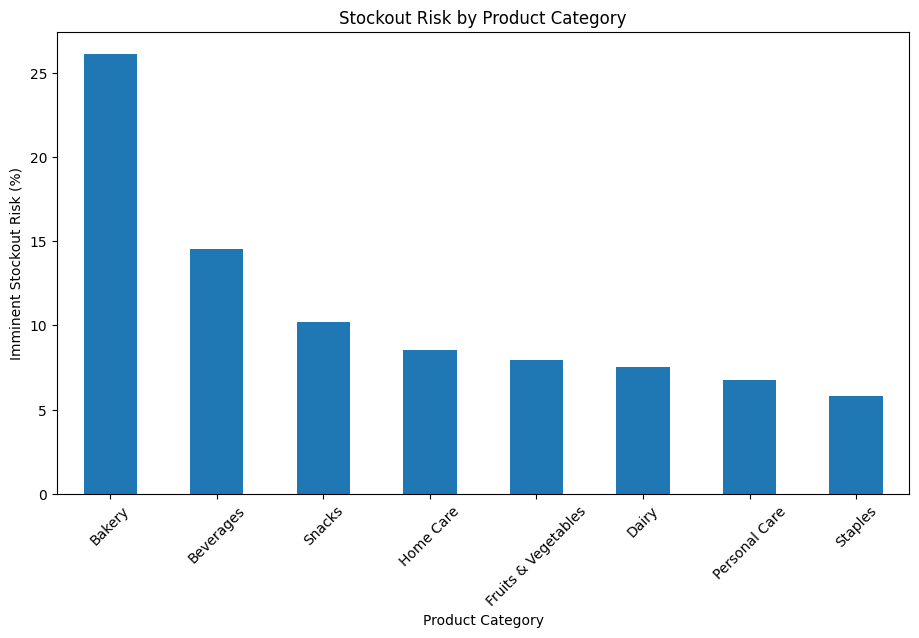

In [36]:
plt.figure(figsize=(11,6))

category_analysis.plot(kind='bar')

plt.title('Stockout Risk by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Imminent Stockout Risk (%)')
plt.xticks(rotation=45)
plt.show()

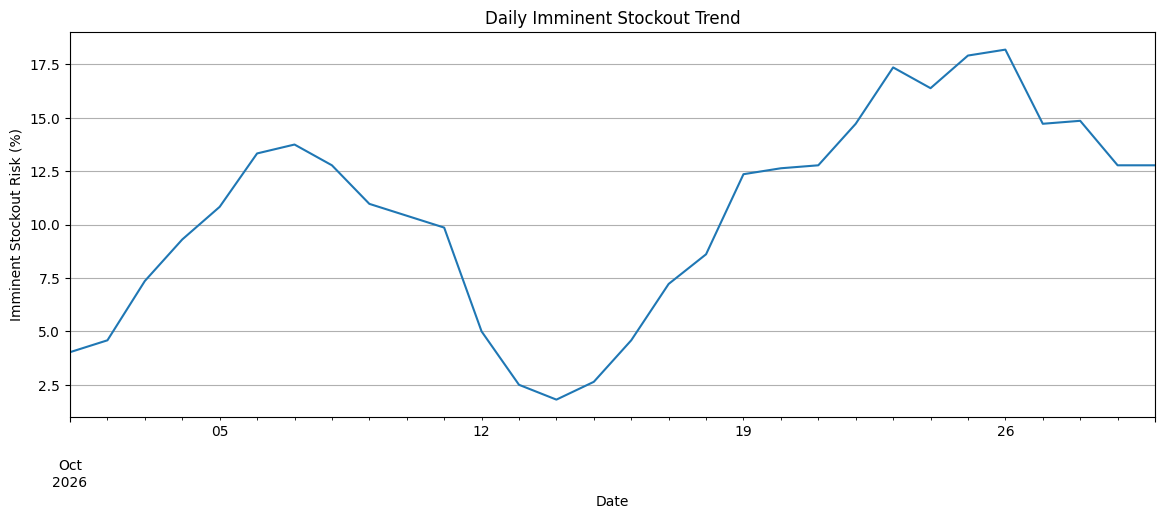

In [37]:
daily_analysis = master.groupby('date').apply(
    lambda x: (x['stockout_risk'] == 'Imminent').mean() * 100,
    include_groups=False
)

plt.figure(figsize=(14,5))

daily_analysis.plot()

plt.title('Daily Imminent Stockout Trend')
plt.xlabel('Date')
plt.ylabel('Imminent Stockout Risk (%)')
plt.grid(True)
plt.show()

In [38]:
# Feature 1: Reorder Gap

master['reorder_gap'] = (
    master['reorder_point'] - master['closing_stock']
)

display(master[['reorder_point',
                'closing_stock',
                'reorder_gap']].head())

,reorder_point,closing_stock,reorder_gap
0,36.4,144.9,-108.5
1,36.4,134.9,-98.5
2,36.4,119.9,-83.5
3,36.4,109.9,-73.5
4,36.4,100.9,-64.5


In [39]:
# Feature 2: Days of Cover Ratio

master['days_of_cover_ratio'] = (
    master['days_of_cover'] /
    master['lead_time_days_expected'].replace(0, np.nan)
)

display(master[['days_of_cover',
                'lead_time_days_expected',
                'days_of_cover_ratio']].head())

,days_of_cover,lead_time_days_expected,days_of_cover_ratio
0,9.66,1,9.66
1,10.79,1,10.79
2,8.99,1,8.99
3,8.79,1,8.79
4,8.55,1,8.55


In [40]:
# Feature 3: Clean Supplier Reliability

master['supplier_reliability_clean'] = master['reliability_score']

print(master['supplier_reliability_clean'].isnull().sum())

0


In [41]:
# Feature 4: Recent Reorder

master = master.sort_values(
    ['store_id', 'sku_id', 'date']
).copy()

master['is_recent_reorder'] = (
    master.groupby(['store_id', 'sku_id'])['reorder_placed']
    .transform(
        lambda x: (
            x.shift(1)
            .map({'Y': 1, 'N': 0})
            .rolling(3, min_periods=1)
            .max()
        )
    )
    .fillna(0)
    .astype(int)
)

display(master[['store_id',
                'sku_id',
                'date',
                'reorder_placed',
                'is_recent_reorder']].head(10))

,store_id,sku_id,date,reorder_placed,is_recent_reorder
0,ST01,SKU001,2026-10-01,N,0
1,ST01,SKU001,2026-10-02,N,0
2,ST01,SKU001,2026-10-03,N,0
3,ST01,SKU001,2026-10-04,N,0
4,ST01,SKU001,2026-10-05,N,0
5,ST01,SKU001,2026-10-06,N,0
6,ST01,SKU001,2026-10-07,N,0
7,ST01,SKU001,2026-10-08,N,0
8,ST01,SKU001,2026-10-09,N,0
9,ST01,SKU001,2026-10-10,N,0


In [42]:
# Feature 5: Day of Month

master['day_of_month'] = master['date'].dt.day

display(master[['date', 'day_of_month']].head())

,date,day_of_month
0,2026-10-01,1
1,2026-10-02,2
2,2026-10-03,3
3,2026-10-04,4
4,2026-10-05,5


In [43]:
# Feature 6: Days Since Festival Start

festival_start = pd.Timestamp('2026-10-22')

master['days_since_festival_start'] = (
    master['date'] - festival_start
).dt.days

display(master[['date',
                'days_since_festival_start']].head())

,date,days_since_festival_start
0,2026-10-01,-21
1,2026-10-02,-20
2,2026-10-03,-19
3,2026-10-04,-18
4,2026-10-05,-17


In [44]:
# Feature 7: One-Hot Encoding

master_encoded = pd.get_dummies(
    master,
    columns=[
        'category',
        'popularity_tier',
        'store_size',
        'event_type'
    ],
    drop_first=True,
    dtype=int
)

print("Original shape:", master.shape)
print("Encoded shape:", master_encoded.shape)

Original shape: (21600, 47)
Encoded shape: (21600, 56)


In [45]:
# Check newly created features

new_features = [
    'reorder_gap',
    'days_of_cover_ratio',
    'supplier_reliability_clean',
    'is_recent_reorder',
    'day_of_month',
    'days_since_festival_start'
]

display(master[new_features].head(10))

print("\nFeature Engineering Completed!")

,reorder_gap,days_of_cover_ratio,supplier_reliability_clean,is_recent_reorder,day_of_month,days_since_festival_start
0,-108.5,9.66,0.83,0,1,-21
1,-98.5,10.79,0.83,0,2,-20
2,-83.5,8.99,0.83,0,3,-19
3,-73.5,8.79,0.83,0,4,-18
4,-64.5,8.55,0.83,0,5,-17
5,-52.5,7.52,0.83,0,6,-16
6,-43.5,6.99,0.83,0,7,-15
7,-30.5,6.01,0.83,0,8,-14
8,-18.5,4.81,0.83,0,9,-13
9,-5.5,3.76,0.83,0,10,-12



Feature Engineering Completed!


In [46]:

# Sort data according to date
master_encoded = master_encoded.sort_values('date').copy()

# Training data: 1 October to 23 October
train_data = master_encoded[
    master_encoded['date'] <= '2026-10-23'
].copy()

# Testing data: 24 October to 30 October
test_data = master_encoded[
    master_encoded['date'] >= '2026-10-24'
].copy()

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)


Training data shape: (16560, 56)
Testing data shape: (5040, 56)


In [47]:

# Separate target column
y_train = train_data['stockout_risk']
y_test = test_data['stockout_risk']

# Columns that should not be used as model features
columns_to_remove = [
    'stockout_risk', 'date',
    'store_id', 'sku_id', 'supplier_id', 'sku_supplier_id'
]

# Select numeric features only
X_train = train_data.drop(
    columns=columns_to_remove, errors='ignore'
).select_dtypes(include=['number', 'bool'])

X_test = test_data.drop(
    columns=columns_to_remove, errors='ignore'
).select_dtypes(include=['number', 'bool'])

# Keep exactly the same feature columns in both datasets
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Fill missing values using training-data medians
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (16560, 38)
X_test: (5040, 38)
y_train: (16560,)
y_test: (5040,)


In [48]:

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training target distribution:
stockout_risk
Safe        10992
At-Risk      4060
Imminent     1508
Name: count, dtype: int64

Testing target distribution:
stockout_risk
Safe        3139
At-Risk     1126
Imminent     775
Name: count, dtype: int64


In [49]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [50]:

# Create the baseline model
baseline_model = DummyClassifier(strategy='most_frequent')

# Train the model
baseline_model.fit(X_train, y_train)

# Make predictions
y_pred_baseline = baseline_model.predict(X_test)

print("Baseline model trained successfully!")


Baseline model trained successfully!


In [51]:

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Accuracy (%):", baseline_accuracy * 100)


Baseline Accuracy: 0.6228174603174603
Baseline Accuracy (%): 62.28174603174603


In [52]:

print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))


              precision    recall  f1-score   support

     At-Risk       0.00      0.00      0.00      1126
    Imminent       0.00      0.00      0.00       775
        Safe       0.62      1.00      0.77      3139

    accuracy                           0.62      5040
   macro avg       0.21      0.33      0.26      5040
weighted avg       0.39      0.62      0.48      5040



In [53]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [54]:

# Create scaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")


Feature scaling completed!


In [55]:

# Create Logistic Regression model
log_model = LogisticRegression(
    solver='lbfgs',
    max_iter=1000
)

# Train the model
log_model.fit(X_train_scaled, y_train)

# Predict on testing data
y_pred_log = log_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [56]:

from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy)
print("Accuracy (%):", log_accuracy * 100)


Logistic Regression Accuracy: 0.9293650793650794
Accuracy (%): 92.93650793650794


In [57]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_log,
    zero_division=0
))


              precision    recall  f1-score   support

     At-Risk       0.87      0.81      0.84      1126
    Imminent       0.83      0.82      0.83       775
        Safe       0.97      1.00      0.99      3139

    accuracy                           0.93      5040
   macro avg       0.89      0.88      0.88      5040
weighted avg       0.93      0.93      0.93      5040



In [58]:

from sklearn.ensemble import RandomForestClassifier


In [59]:

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [60]:

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("Accuracy (%):", rf_accuracy * 100)


Random Forest Accuracy: 0.9418650793650793
Accuracy (%): 94.18650793650794


In [61]:

print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))


              precision    recall  f1-score   support

     At-Risk       0.81      0.96      0.88      1126
    Imminent       0.93      0.69      0.79       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.94      5040
   macro avg       0.91      0.88      0.89      5040
weighted avg       0.95      0.94      0.94      5040



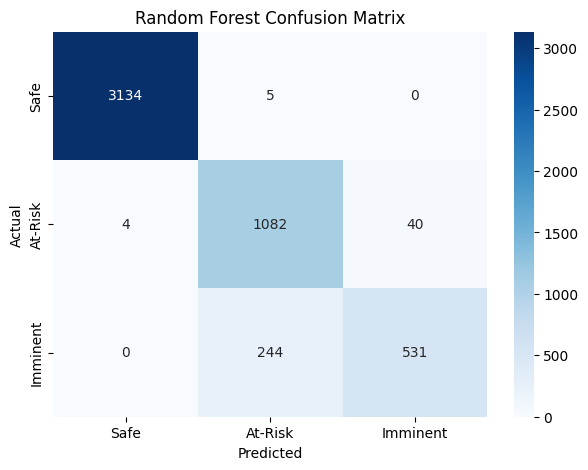

In [62]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['Safe', 'At-Risk', 'Imminent']
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Safe', 'At-Risk', 'Imminent'],
    yticklabels=['Safe', 'At-Risk', 'Imminent']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()


In [63]:

from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd


In [64]:

# Compare model performance
comparison = pd.DataFrame({
    'Model': [
        'Majority Class Baseline',
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Imminent Recall': [
        recall_score(y_test, y_pred_baseline,
                     labels=['Imminent'], average=None,
                     zero_division=0)[0],
        recall_score(y_test, y_pred_log,
                     labels=['Imminent'], average=None,
                     zero_division=0)[0],
        recall_score(y_test, y_pred_rf,
                     labels=['Imminent'], average=None,
                     zero_division=0)[0]
    ],
    'Weighted F1-Score': [
        f1_score(y_test, y_pred_baseline,
                 average='weighted', zero_division=0),
        f1_score(y_test, y_pred_log,
                 average='weighted', zero_division=0),
        f1_score(y_test, y_pred_rf,
                 average='weighted', zero_division=0)
    ]
})

print(comparison.round(4))


                     Model  Accuracy  Imminent Recall  Weighted F1-Score
0  Majority Class Baseline    0.6228           0.0000             0.4781
1      Logistic Regression    0.9294           0.8206             0.9281
2            Random Forest    0.9419           0.6852             0.9400


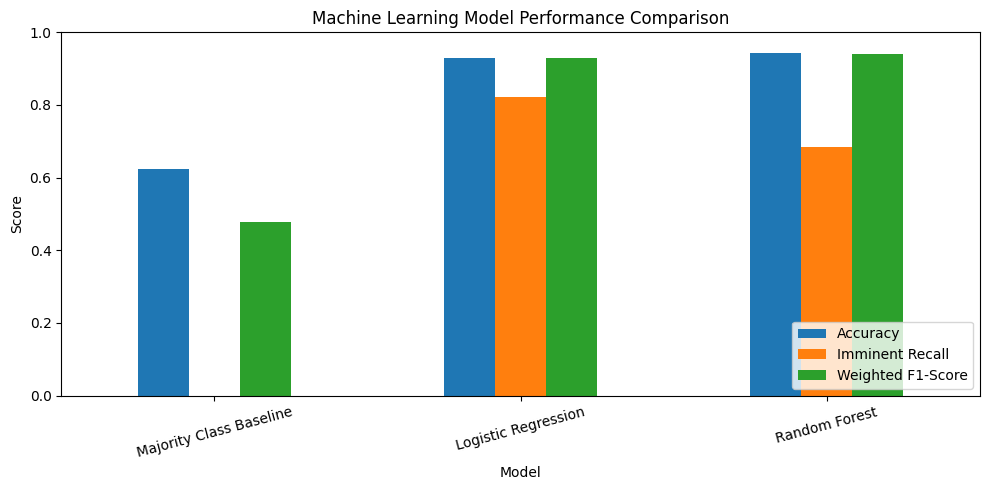

In [65]:

comparison.set_index('Model')[[
    'Accuracy', 'Imminent Recall', 'Weighted F1-Score'
]].plot(kind='bar', figsize=(10, 5))

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


TOP 15 FEATURES INFLUENCING STOCKOUT RISK:


,Feature,Importance
8,days_of_cover,0.212218
20,days_of_cover_ratio,0.188698
19,reorder_gap,0.187297
3,closing_stock,0.054621
6,lead_time_days_actual,0.047573
0,opening_stock,0.030712
7,sales_velocity_7d,0.026026
4,reorder_point,0.021226
21,supplier_reliability_clean,0.020814
14,reliability_score,0.018381


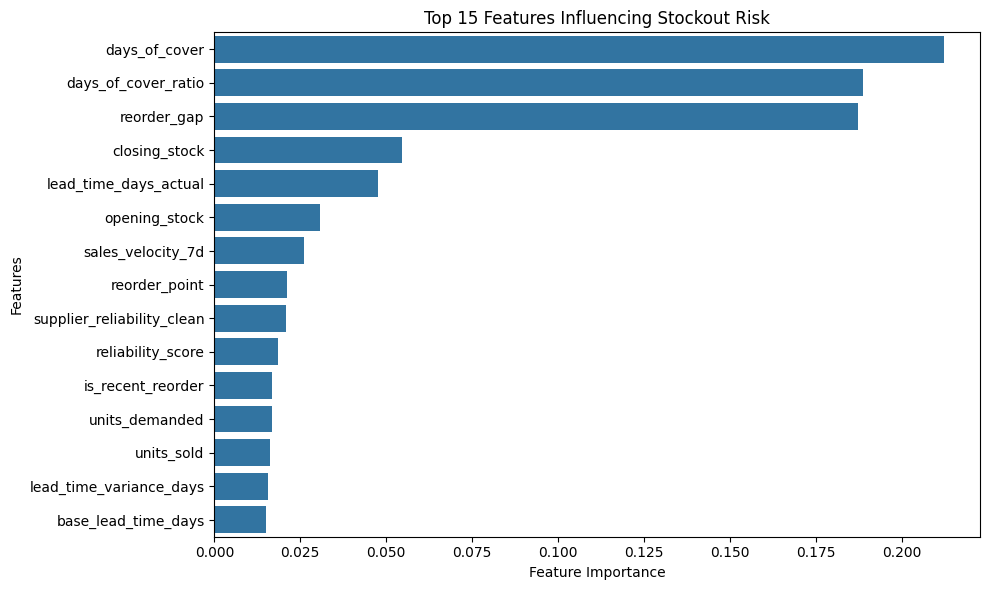

In [66]:

# STEP 13: RANDOM FOREST FEATURE IMPORTANCE

# 1. Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# 2. Sort features from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# 3. Display top 15 important features
print("TOP 15 FEATURES INFLUENCING STOCKOUT RISK:")
display(feature_importance.head(15))

# 4. Visualise top 15 features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Influencing Stockout Risk')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


========== RANDOM FOREST FINAL EVALUATION ==========

Accuracy: 94.19 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.81      0.96      0.88      1126
    Imminent       0.93      0.69      0.79       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.94      5040
   macro avg       0.91      0.88      0.89      5040
weighted avg       0.95      0.94      0.94      5040

Imminent Stockout Recall: 68.52 %


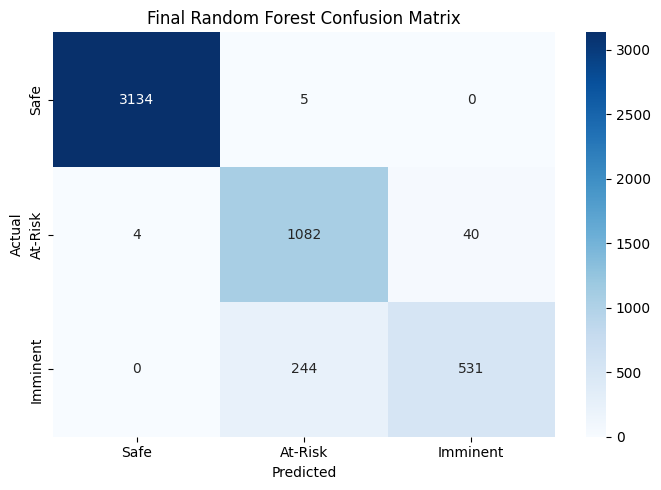


========== BUSINESS INSIGHTS ==========

Imminent Risk by Festival Week:
is_festival_week
N     9.51
Y    23.31
Name: stockout_risk, dtype: float64

Imminent Risk by Perishable Status:
is_perishable
N     9.30
Y    12.77
Name: stockout_risk, dtype: float64

Imminent Risk by Supplier Reliability:
Supplier reliability category not found. Use the earlier reliability analysis.


In [67]:

# STEP 14: FINAL MODEL EVALUATION AND BUSINESS INSIGHTS

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    recall_score,
    f1_score
)

# 1. Final model accuracy
print("========== RANDOM FOREST FINAL EVALUATION ==========")

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

# 2. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

# 3. Imminent class recall
imminent_recall = recall_score(
    y_test,
    y_pred_rf,
    labels=['Imminent'],
    average=None,
    zero_division=0
)[0]

print("Imminent Stockout Recall:",
      round(imminent_recall * 100, 2), "%")

# 4. Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['Safe', 'At-Risk', 'Imminent']
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Safe', 'At-Risk', 'Imminent'],
    yticklabels=['Safe', 'At-Risk', 'Imminent']
)
plt.title("Final Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 5. Business insight: festival impact
festival_impact = master.groupby(
    'is_festival_week'
)['stockout_risk'].apply(
    lambda x: (x == 'Imminent').mean() * 100
)

print("\n========== BUSINESS INSIGHTS ==========")
print("\nImminent Risk by Festival Week:")
print(festival_impact.round(2))

# 6. Business insight: perishable products
perishable_impact = master.groupby(
    'is_perishable'
)['stockout_risk'].apply(
    lambda x: (x == 'Imminent').mean() * 100
)

print("\nImminent Risk by Perishable Status:")
print(perishable_impact.round(2))

# 7. Business insight: supplier reliability
print("\nImminent Risk by Supplier Reliability:")
print(master.groupby('supplier_reliability_category')[
    'stockout_risk'
].apply(
    lambda x: (x == 'Imminent').mean() * 100
).round(2) if 'supplier_reliability_category' in master.columns
else "Supplier reliability category not found. Use the earlier reliability analysis.")


In [68]:

# STEP 15: FINAL PROJECT SUMMARY AND CONCLUSION

# 1. Calculate final model metrics
accuracy = accuracy_score(y_test, y_pred_rf) * 100

imminent_recall = recall_score(
    y_test,
    y_pred_rf,
    labels=['Imminent'],
    average=None,
    zero_division=0
)[0] * 100

weighted_f1 = f1_score(
    y_test, y_pred_rf,
    average='weighted',
    zero_division=0
)

# 2. Calculate business insights
festival_rates = master.groupby('is_festival_week')[
    'stockout_risk'
].apply(lambda x: (x == 'Imminent').mean() * 100)

perishable_rates = master.groupby('is_perishable')[
    'stockout_risk'
].apply(lambda x: (x == 'Imminent').mean() * 100)

# 3. Display final summary
print("=" * 60)
print("       QUICKCART STOCKOUT RISK - FINAL PROJECT")
print("=" * 60)

print("\nPROJECT OBJECTIVE:")
print("Predict whether inventory is Safe, At-Risk, or Imminent.")

print("\nDATASET:")
print("Total records:", len(master))
print("Total stores:", master['store_id'].nunique())
print("Total SKUs:", master['sku_id'].nunique())

print("\nMODEL PERFORMANCE:")
print("Selected model: Random Forest")
print("Accuracy:", round(accuracy, 2), "%")
print("Imminent Recall:", round(imminent_recall, 2), "%")
print("Weighted F1-Score:", round(weighted_f1, 4))

print("\nFESTIVAL IMPACT:")
print(festival_rates.round(2))

print("\nPERISHABLE PRODUCT IMPACT:")
print(perishable_rates.round(2))

print("\nTOP 5 IMPORTANT FEATURES:")
print(feature_importance.head(5).to_string(index=False))

print("\n" + "=" * 60)
print("FINAL CONCLUSION")
print("=" * 60)

print("""
The QuickCart Stockout Risk project uses historical inventory,
store, SKU, supplier and event information to predict stockout risk.

The dataset was cleaned, merged and prepared through feature
engineering. Three classification approaches were evaluated:
Majority Class Baseline, Logistic Regression and Random Forest.

Random Forest was evaluated using accuracy, precision, recall,
F1-score and a confusion matrix. Imminent-class recall is
particularly important because missed stockout warnings can
cause product shortages.

The business analysis also examines festival demand and
perishable products to help inventory teams understand
important stockout-risk patterns.

This project demonstrates how machine learning can support
better inventory planning and reduce stockout risk.
""")

print("=" * 60)
print("PROJECT ANALYSIS COMPLETED")
print("=" * 60)


       QUICKCART STOCKOUT RISK - FINAL PROJECT

PROJECT OBJECTIVE:
Predict whether inventory is Safe, At-Risk, or Imminent.

DATASET:
Total records: 21600
Total stores: 12
Total SKUs: 60

MODEL PERFORMANCE:
Selected model: Random Forest
Accuracy: 94.19 %
Imminent Recall: 68.52 %
Weighted F1-Score: 0.94

FESTIVAL IMPACT:
is_festival_week
N     9.51
Y    23.31
Name: stockout_risk, dtype: float64

PERISHABLE PRODUCT IMPACT:
is_perishable
N     9.30
Y    12.77
Name: stockout_risk, dtype: float64

TOP 5 IMPORTANT FEATURES:
              Feature  Importance
        days_of_cover    0.212218
  days_of_cover_ratio    0.188698
          reorder_gap    0.187297
        closing_stock    0.054621
lead_time_days_actual    0.047573

FINAL CONCLUSION

The QuickCart Stockout Risk project uses historical inventory,
store, SKU, supplier and event information to predict stockout risk.

The dataset was cleaned, merged and prepared through feature
engineering. Three classification approaches were evaluated